# Inverting for the ELA with the IGM ice-flow emulator

This notebook recovers a glacier's **equilibrium line altitude** from an
observed thickness field, using the pretrained IGM emulator (`SIADecompNet`)
for ice dynamics.

The surface mass balance follows the linear ELA law

$$b(z) = \min\bigl(\nabla b \,(z - z_{\mathrm{ELA}}),\; b_{\max}\bigr)$$

and $z_{\mathrm{ELA}}$ is the single scalar we invert for. Gradients travel
from the simulated thickness, back through every time step *and through the
emulator*, to the ELA — so plain Adam is enough.

**Ice dynamics.** `forward_scheme='igm'` runs the emulator, whose sliding is the
Weertman law parameterized by the reference basal shear stress `tau_ref` (MPa):
lower `tau_ref` means easier sliding, hence faster flow. The alternative,
`forward_scheme='SIA'`, is shallow ice with internal deformation only and no
sliding at all.

All of the machinery lives in `core/`; the notebook only wires it together.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import netCDF4

from config.read_config import parse_arguments
from core.emulator import load_emulator
from core.glacier import GlacierDynamicsCheckpointed
from core.inversion import invert_ela
from core.smb import update_smb_ELA
from visualization.plots import plot_ela_convergence, plot_thickness_comparison

%matplotlib inline

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device: {device}')

/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


device: cuda


## 1. The ice-flow emulator

`load_emulator` reads an IGM artifact directory — `manifest.yaml` plus
`export/weights.weights.h5` — and rebuilds it as a PyTorch module. The manifest
pins the architecture, the frozen input-normalization statistics and the output
scale, so the artifact is used exactly as IGM wrote it.

Its weights are frozen: gradients flow *through* the emulator to the ELA, but
never accumulate into the network itself.

In [2]:
args = parse_arguments([])          # defaults, then override below
args.forward_scheme = 'igm'

emulator = load_emulator(args.emulator_path, device=device)

print(f'artifact       : {args.emulator_path}')
print(f'inputs         : {emulator.input_names}')
print(f'vertical basis : {emulator.manifest.basis_vertical} with Nz={emulator.Nz}')
print(f'column weights : {[round(w, 3) for w in emulator.V_bar.tolist()]}  '
      f'(ubar = 0.2*U_bed + 0.8*U_surf)')
print(f'trainable      : {any(p.requires_grad for p in emulator.parameters())}')

artifact       : emulators/SIADecompNet_18x80_dil1-32
inputs         : ['thk', 'usurf', 'tau_ref', 'arrhenius', 'dX']
vertical basis : molho with Nz=2
column weights : [0.2, 0.8]  (ubar = 0.2*U_bed + 0.8*U_surf)
trainable      : False


## 2. Geometry and forcing

Aletsch, on a 100 m grid. We start from the 1880 surface and run 20 years.

`tau_ref` and `arrhenius` are uniform here, taken from `args`. Both accept a
2D tensor instead, which is how they would become inversion controls of their
own.

In [3]:
nc = netCDF4.Dataset('./data/geology.nc')
topo = torch.tensor(nc.variables['topg'][:], device=device, dtype=torch.float32)
H_init = torch.tensor(nc.variables['surf_1880'][:], device=device, dtype=torch.float32) - topo
icemask = torch.tensor(nc.variables['icemask'][:], device=device, dtype=torch.float32)
nc.close()

H_init = torch.clamp(H_init, min=0.0)   # the DEM difference dips slightly negative

args.t_start = torch.tensor(1880.0)
args.ttot = torch.tensor(1900.0)
args.vis_freq = 100.0                    # no intermediate SMB updates: ELA is constant
args.cfl = 0.2

print(f'grid            : {tuple(topo.shape)} at dx={args.dx} m')
print(f'bed elevation   : {topo.min():.0f} to {topo.max():.0f} m')
print(f'initial ice     : max {H_init.max():.0f} m, '
      f'volume {H_init.sum() * args.dx * args.dy / 1e9:.2f} km3')
print(f'period          : {args.t_start.item():.0f} to {args.ttot.item():.0f}')
print(f'tau_ref         : {args.tau_ref} MPa   (Weertman reference basal shear stress)')
print(f'arrhenius       : {args.arrhenius} MPa^-3 yr^-1')

grid            : (225, 132) at dx=100 m
bed elevation   : 799 to 4154 m
initial ice     : max 921 m, volume 20.67 km3
period          : 1880 to 1900
tau_ref         : 0.2154 MPa   (Weertman reference basal shear stress)
arrhenius       : 78.0 MPa^-3 yr^-1


In [4]:
glacier_model = GlacierDynamicsCheckpointed(
    Z_topo=topo,
    H_init=H_init,
    ice_mask=icemask,
    device=device,
    args=args,
    emulator=emulator,
    visualize=False,
)

### A look at the velocity field

Worth one glance before inverting: if the emulator's speeds are wrong, every
number downstream is wrong too. Aletsch's trunk flows at roughly 50–200 m/yr.

depth-averaged speed on ice (m/yr):
  p50      93.4
  p90     247.0
  p99     679.7
  max    2850.0   <- margin artifact, see note above
  pixels above 500 m/yr: 234 of 9611


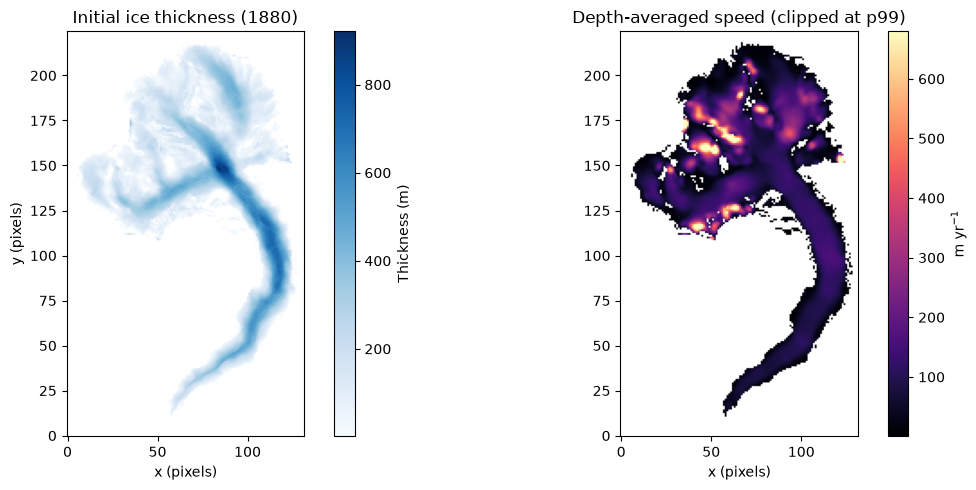

In [5]:
with torch.no_grad():
    ubar, vbar = emulator.velocities(
        thk=H_init,
        usurf=topo + H_init,
        tau_ref=glacier_model.tau_ref,
        arrhenius=glacier_model.arrhenius,
        dX=glacier_model.dX,
    )
speed = torch.sqrt(ubar ** 2 + vbar ** 2)
on_ice = H_init > 1.0
print('depth-averaged speed on ice (m/yr):')
for q in (0.5, 0.9, 0.99):
    print(f'  p{int(q * 100):<3d} {speed[on_ice].quantile(q):8.1f}')
print(f'  max  {speed.max():8.1f}   <- margin artifact, see note above')
print(f'  pixels above 500 m/yr: {int((speed[on_ice] > 500).sum())} '
      f'of {int(on_ice.sum())}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im = axes[0].imshow(np.where(H_init.cpu() > 1, H_init.cpu(), np.nan), cmap='Blues', origin='lower')
axes[0].set_title('Initial ice thickness (1880)')
fig.colorbar(im, ax=axes[0], label='Thickness (m)')

im = axes[1].imshow(np.where(on_ice.cpu(), speed.cpu(), np.nan), cmap='magma',
                    origin='lower', vmax=float(speed[on_ice].quantile(0.99)))
axes[1].set_title('Depth-averaged speed (clipped at p99)')
fig.colorbar(im, ax=axes[1], label='m yr$^{-1}$')
for ax in axes:
    ax.set_xlabel('x (pixels)')
axes[0].set_ylabel('y (pixels)')
plt.tight_layout()
plt.show()

## 3. A synthetic observation

Run the forward model once with a known ELA and keep the result. Inverting
against synthetic data is the honest way to check the machinery: we know the
answer, so we can tell convergence from wishful thinking.

In [6]:
ELA_TRUE = torch.tensor(2900.0, device=device)
GRAD_B = torch.tensor(0.005, device=device)    # m ice eq. per m of elevation
B_MAX = torch.tensor(2.0, device=device)       # cap on accumulation, m ice eq./yr

with torch.no_grad():
    observation = glacier_model(
        precip_tensor=None, T_m_lowest=None, T_s=None, melt_factor=None,
        smb_method='ELA', ELA=ELA_TRUE, grad_b=GRAD_B, b_max=B_MAX,
    )

print(f'true ELA          : {ELA_TRUE.item():.0f} m')
print(f'observed thickness: max {observation.max():.0f} m, '
      f'volume {observation.sum() * args.dx * args.dy / 1e9:.2f} km3')

/home/klleshi/Documents/InvertedGlacierEvolutionModel/core/glacier.py:113: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t_last_update = torch.tensor(self.t_start, device=self.device)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/_dynamo/eval_frame.py:745: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. In version 2.5 we will raise an exception if use_reentrant is not passed. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/home/klleshi/miniconda3/envs/IGEM/lib/python3.12/site-packages/torch/utils/checkpoint.py:87: UserWarning: None of the inputs have requires_grad=True. Gradients will b

true ELA          : 2900 m
observed thickness: max 1005 m, volume 21.37 km3


## 4. Invert

`invert_ela` runs the forward model and returns the masked misfit together with
diagnostics. Anything passed with `requires_grad` is a control; here that is the
ELA alone, with the gradient and the cap held fixed.

Starting 300 m too high, so the optimizer has to walk the ELA down.

In [7]:
ela = torch.tensor(3200.0, device=device, requires_grad=True)

# Two deliberate choices, both about a *scalar* control:
#
#  * betas=(0.5, 0.9) cuts Adam's momentum. With the defaults the optimizer
#    reaches the answer around iteration 9 and then sails straight past it,
#    finishing ~43 m low. Momentum is an asset on noisy high-dimensional
#    problems and a liability on one smooth scalar.
#  * Adam's step size stays near `lr` however small the gradient gets, so it
#    cannot settle on its own. The decay does that for it.
#
# Plain SGD is monotone here and never overshoots, but converges far too slowly:
# at lr=4 it was still 43 m out after 20 iterations.
optimizer = torch.optim.Adam([ela], lr=40.0, betas=(0.5, 0.9))
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=6, gamma=0.40)

loss_history, ela_history = [], []

for iteration in range(24):
    optimizer.zero_grad()
    H_sim, loss, data_term, metrics = invert_ela(
        ela, GRAD_B, B_MAX, observation, glacier_model)
    loss.backward()
    optimizer.step()
    scheduler.step()

    loss_history.append(loss.item())
    ela_history.append(ela.item())
    if iteration % 2 == 0 or iteration == 23:
        print(f'iter {iteration + 1:3d}   ELA {ela.item():7.1f} m   '
              f'loss {loss.item():10.3f} m^2   RMSE {metrics["rmse"].item():6.2f} m')

print(f'\nrecovered ELA {ela.item():.1f} m   vs true {ELA_TRUE.item():.0f} m   '
      f'(error {abs(ela.item() - ELA_TRUE.item()):.1f} m)')

iter   1   ELA  3160.0 m   loss   1018.906 m^2   RMSE  31.92 m


iter   3   ELA  3083.1 m   loss    562.657 m^2   RMSE  23.72 m


iter   5   ELA  3014.7 m   loss    255.026 m^2   RMSE  15.97 m


iter   7   ELA  2975.1 m   loss     86.577 m^2   RMSE   9.30 m


iter   9   ELA  2957.6 m   loss     51.992 m^2   RMSE   7.21 m


iter  11   ELA  2942.7 m   loss     29.693 m^2   RMSE   5.45 m


... (3 outputs left out)

iter  19   ELA  2922.2 m   loss      6.321 m^2   RMSE   2.51 m


iter  21   ELA  2920.6 m   loss      5.488 m^2   RMSE   2.34 m


iter  23   ELA  2919.0 m   loss      4.710 m^2   RMSE   2.17 m


iter  24   ELA  2918.1 m   loss      4.337 m^2   RMSE   2.08 m

recovered ELA 2918.1 m   vs true 2900 m   (error 18.1 m)


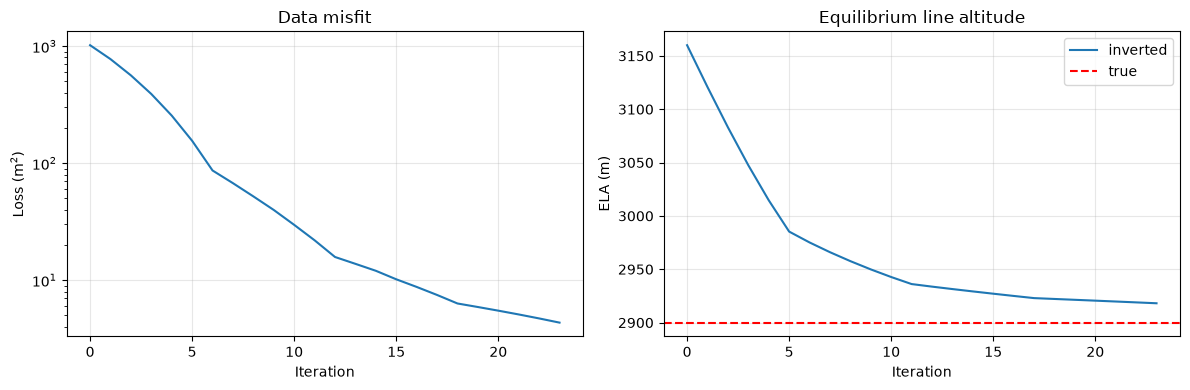

In [8]:
plot_ela_convergence(loss_history, ela_history, ela_true=ELA_TRUE)
plt.show()

## 5. Does the recovered ELA reproduce the observation?

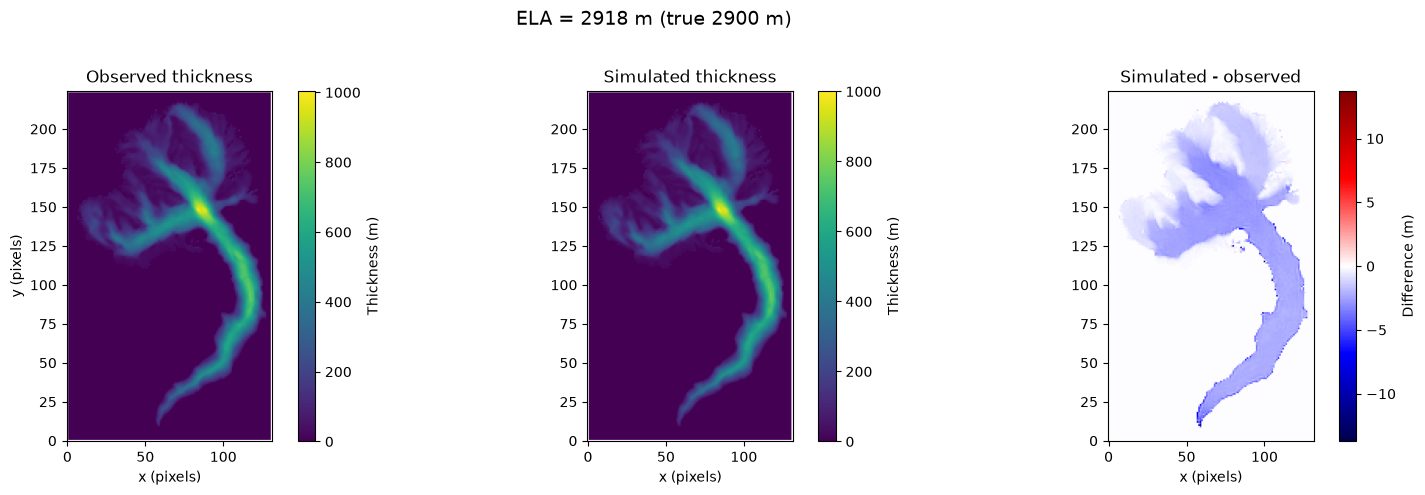

residual over glaciated pixels: mean -1.712 m, RMSE 1.994 m, max |.| 13.741 m


In [9]:
with torch.no_grad():
    H_final = glacier_model(
        precip_tensor=None, T_m_lowest=None, T_s=None, melt_factor=None,
        smb_method='ELA', ELA=ela.detach(), grad_b=GRAD_B, b_max=B_MAX,
    )

plot_thickness_comparison(H_final, observation,
                          title=f'ELA = {ela.item():.0f} m (true {ELA_TRUE.item():.0f} m)')
plt.show()

residual = (H_final - observation)[observation > 1.0]
print(f'residual over glaciated pixels: mean {residual.mean():+.3f} m, '
      f'RMSE {residual.pow(2).mean().sqrt():.3f} m, max |.| {residual.abs().max():.3f} m')

## 6. The mass-balance field it implies

`update_smb_ELA` is the same function the forward model calls, so this is
exactly the forcing the inversion settled on.

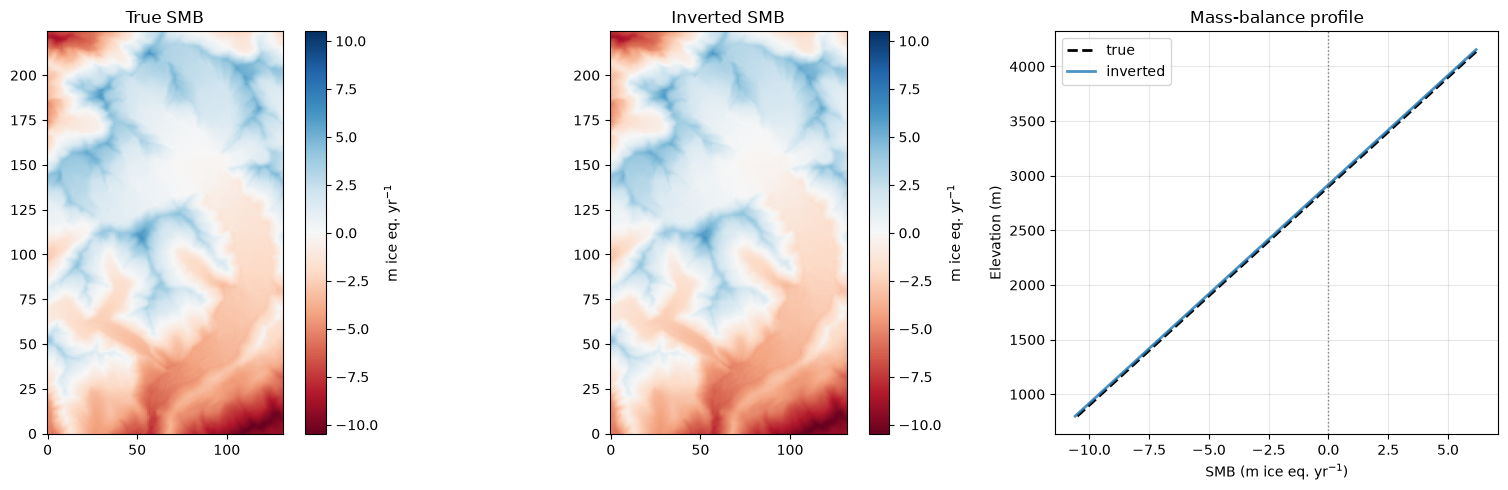

In [10]:
Z_surf = topo + H_final
smb_true = update_smb_ELA(topo + observation, ELA_TRUE, GRAD_B, B_MAX)
smb_inv = update_smb_ELA(Z_surf, ela.detach(), GRAD_B, B_MAX)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
limit = float(torch.max(smb_true.abs()))
for ax, (field, name) in zip(axes[:2], [(smb_true, 'True SMB'), (smb_inv, 'Inverted SMB')]):
    im = ax.imshow(field.cpu(), cmap='RdBu', origin='lower', vmin=-limit, vmax=limit)
    ax.set_title(name)
    fig.colorbar(im, ax=ax, label='m ice eq. yr$^{-1}$')

elevations = np.linspace(float(topo.min()), float(topo.max()), 200)
z = torch.tensor(elevations, device=device, dtype=torch.float32)
axes[2].plot(update_smb_ELA(z, ELA_TRUE, GRAD_B, B_MAX).cpu(), elevations,
             'k--', lw=2, label='true')
axes[2].plot(update_smb_ELA(z, ela.detach(), GRAD_B, B_MAX).cpu(), elevations,
             'tab:blue', lw=2, alpha=0.8, label='inverted')
axes[2].axvline(0, color='grey', ls=':', lw=1)
axes[2].set_xlabel('SMB (m ice eq. yr$^{-1}$)')
axes[2].set_ylabel('Elevation (m)')
axes[2].set_title('Mass-balance profile')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Notes

**Why it stops a few tens of metres out, and why that is fine.** Two reasons,
neither of them a bug. The minimum is genuinely flat: the residual thickness
RMSE printed above is a couple of metres on a glacier close to a kilometre
thick, far below the uncertainty of any real surface DEM. And the adjoint is
approximate once the CFL limiter is active (see below), so the gradient itself
carries error of order 20% as the misfit gets small — grinding further would be
chasing noise, not signal.

**Non-uniqueness.** ELA, gradient and cap trade off against each other: a higher
ELA with a steeper gradient can produce nearly the same thickness field. Only
the ELA is inverted here, with the other two fixed at their true values. Freeing
more than one needs either several observation epochs or a prior.

**The adjoint is approximate in one place.** The time step
`dt = min(cfl*dx/vel_max, dtmax)` reads `vel_max` through `.item()`, so autograd
treats the step length as a constant. The gradient keeps the right sign and
magnitude but is not exact. Setting `args.cfl` large enough that `dt == dtmax`
every step makes it exact, at the cost of stability on fast-flowing ice.

**Swapping the ice dynamics.** Pass `forward_scheme='SIA'` to any of the calls
above to compare against shallow ice with no sliding. It is roughly 30x slower
here and cannot represent sliding, but it depends on no learned model.

**Varying tau_ref in space.** Give `GlacierDynamicsCheckpointed` a 2D tensor as
`tau_ref=`; add `requires_grad_()` and it becomes an inversion control alongside
(or instead of) the ELA.

**If the run is slow.** The time step is set by the fastest pixel anywhere in
the domain, so the margin artifacts noted in section 2 throttle everything. Set
`args.max_velbar` (say 400 m/yr for Aletsch) to cap the depth-averaged speed and
the step size recovers.

## 7. Watching it grow

A sanity check for the eyes rather than the optimizer: start from **bare
bedrock**, hold the ELA at **2900 m**, and run **50 years**. Nothing here is
inverted -- it is just the forward model, so you can see whether ice accumulates
where it should and flows the way a glacier ought to.

`save_times` returns the thickness at each requested time. Velocities are not
stored during the run, so they are recomputed from each saved state; the
emulator is deterministic, so these are exactly the velocities that drove the
run at that moment.

This is quicker than the inversion above despite covering more years: starting
from bare rock there are no DEM margin cliffs, so nothing forces the CFL time
step down and it stays at `dtmax`.

In [11]:
from visualization.plots import plot_evolution

args_grow = parse_arguments([])
args_grow.forward_scheme = 'igm'
args_grow.t_start = torch.tensor(0.0)
args_grow.ttot = torch.tensor(200.0)
args_grow.vis_freq = 1000.0          # the ELA forcing is constant, no need to refresh

glacier_grow = GlacierDynamicsCheckpointed(
    Z_topo=topo,
    H_init=torch.zeros_like(topo),   # ice free
    ice_mask=icemask,
    device=device,
    args=args_grow,
    emulator=emulator,
    visualize=False,
)

snapshot_times = [100.0, 20.0, 40.0, 60.0, 200.0]

with torch.no_grad():
    saved, H_end = glacier_grow.forward(
        precip_tensor=None, T_m_lowest=None, T_s=None, melt_factor=None,
        smb_method='ELA',
        ELA=torch.tensor(2900.0, device=device), grad_b=GRAD_B, b_max=B_MAX,
        save_times=snapshot_times,
    )

thickness_frames, speed_frames = [], []
for t in snapshot_times:
    H_t = saved[t]
    with torch.no_grad():
        u_t, v_t = emulator.velocities(
            thk=H_t, usurf=topo + H_t,
            tau_ref=glacier_grow.tau_ref,
            arrhenius=glacier_grow.arrhenius,
            dX=glacier_grow.dX,
        )
    thickness_frames.append(H_t)
    speed_frames.append(torch.sqrt(u_t ** 2 + v_t ** 2))

    on_ice = H_t > 1.0
    print(f't = {t:5.0f} yr   volume {H_t.sum() * args.dx * args.dy / 1e9:6.3f} km3   '
          f'area {on_ice.sum() * args.dx * args.dy / 1e6:6.1f} km2   '
          f'max thickness {H_t.max():6.1f} m   '
          f'median speed {speed_frames[-1][on_ice].median():5.1f} m/yr')

t =   100 yr   volume  8.126 km3   area   73.7 km2   max thickness  702.9 m   median speed  38.6 m/yr
t =    20 yr   volume  1.611 km3   area   52.0 km2   max thickness  127.1 m   median speed  21.0 m/yr
t =    40 yr   volume  3.616 km3   area   60.7 km2   max thickness  244.4 m   median speed  30.9 m/yr
t =    60 yr   volume  5.417 km3   area   66.4 km2   max thickness  338.7 m   median speed  34.1 m/yr
t =   200 yr   volume 11.679 km3   area   82.5 km2   max thickness  821.2 m   median speed  41.9 m/yr


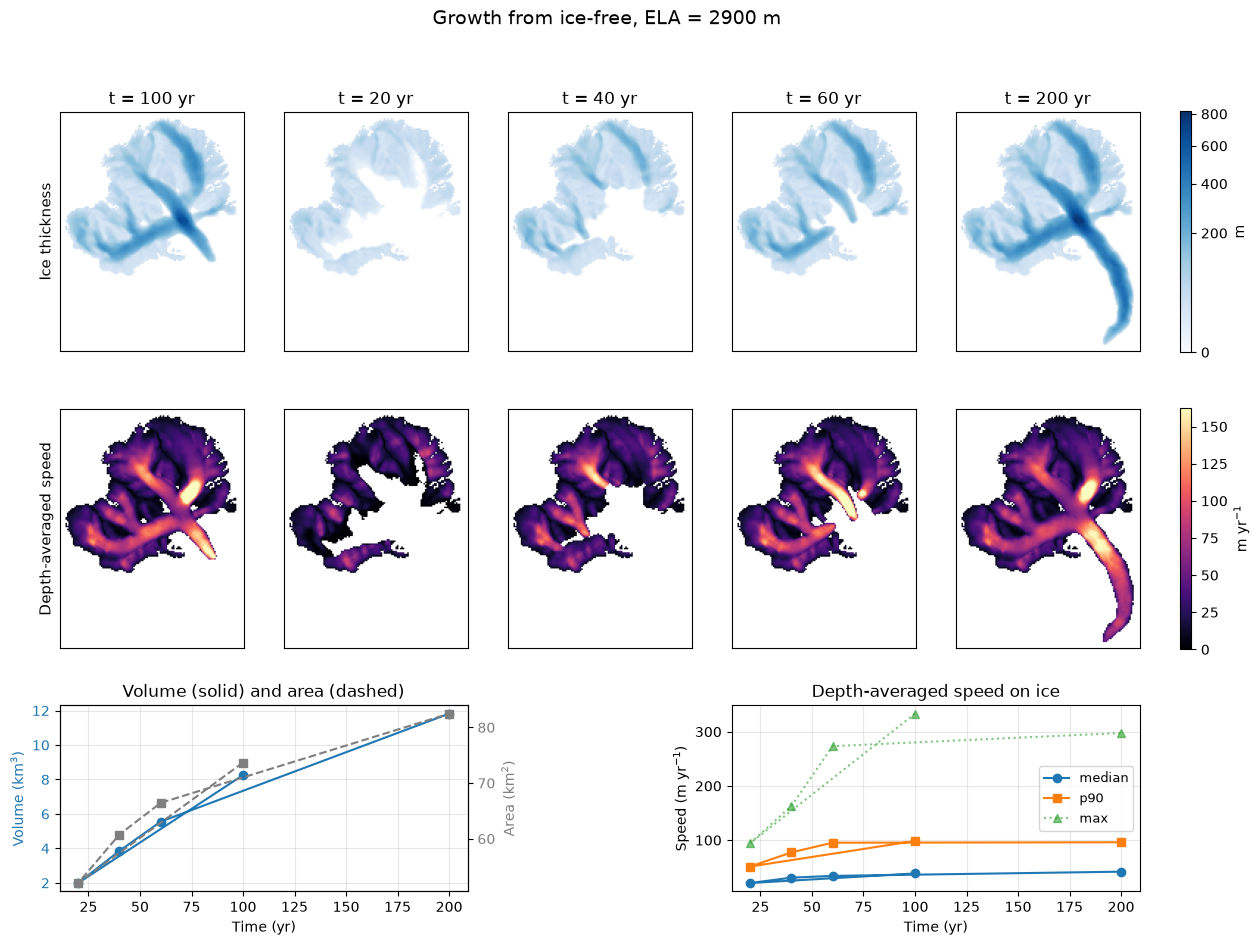

In [12]:
plot_evolution(snapshot_times, thickness_frames, speed_frames, dx=float(args.dx),
               title='Growth from ice-free, ELA = 2900 m')
plt.show()